# Every asteroid orbit, and Rubin-era discoveries

**Question:** What does the asteroid belt look like when we plot all ~1.5 million known orbits, and where do near-Earth objects and this year's discoveries fall?

**Data:** [MPCORB](https://www.minorplanetcenter.net/iau/MPCORB.html) from the Minor Planet Center (IAU), the master file of every known asteroid orbit. It is downloaded once by `starters/10_mpc_orbits.py` into `data/`.

In [1]:
import os, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == 'project10':
    os.chdir('..')                                   # run from the project root so data/ is found

# fixed-width columns from the MPC format page: e, a, flags, readable name/designation
df = pd.read_fwf('data/MPCORB.DAT.gz', colspecs=[(70, 79), (92, 103), (161, 165), (166, 194)],
                 names=['e', 'a', 'flags', 'name'], skiprows=43, dtype=str, compression='gzip')
df['a'], df['e'] = pd.to_numeric(df['a'], errors='coerce'), pd.to_numeric(df['e'], errors='coerce')
df = df.dropna(subset=['a', 'e'])
print(f'{len(df):,} asteroids')

1,580,046 asteroids


## 1. Orbit size vs. eccentricity
`a` is orbit size in au (1 au = Earth-Sun distance). `e` is how stretched the orbit is (0 = circle). Near-Earth objects (NEOs) are red; asteroids designated in 2026 are blue.

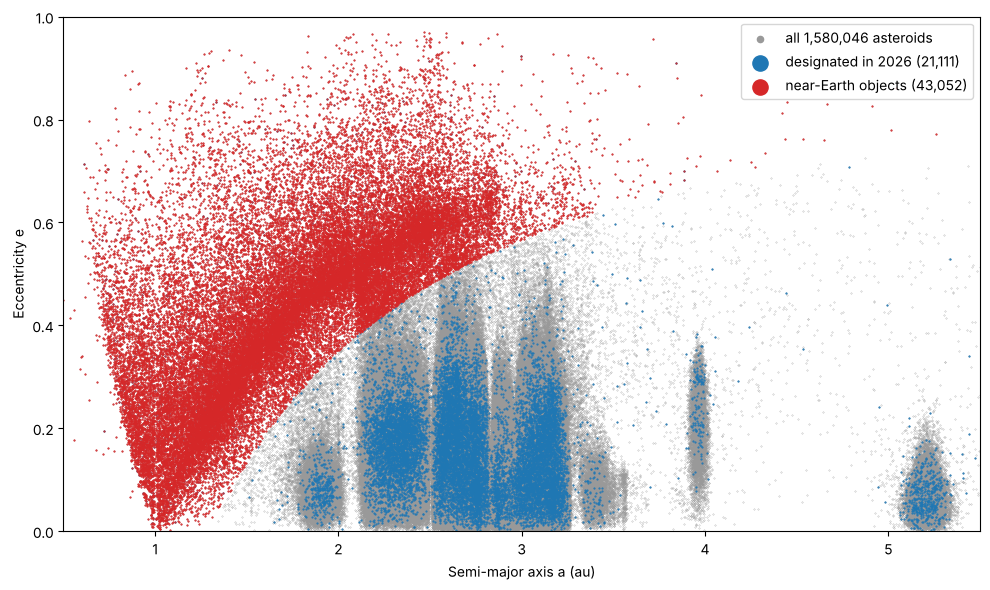

In [2]:
neo = df['flags'].fillna('0').apply(int, base=16) & 0x0800 > 0      # MPC flag bit 11 = NEO
new = df['name'].str.contains(r'(?:^|\) )2026 ', na=False)            # 2026 designations (incl. numbered ones)
plt.figure(figsize=(10, 6))
plt.scatter(df.a, df.e, s=0.05, c='0.6', rasterized=True, label=f'all {len(df):,} asteroids')
plt.scatter(df.a[new], df.e[new], s=0.3, c='tab:blue', rasterized=True, label=f'designated in 2026 ({new.sum():,})')
plt.scatter(df.a[neo], df.e[neo], s=0.3, c='tab:red', rasterized=True, label=f'near-Earth objects ({neo.sum():,})')
plt.xlim(0.5, 5.5); plt.ylim(0, 1); plt.xlabel('Semi-major axis a (au)'); plt.ylabel('Eccentricity e')
plt.legend(markerscale=20, loc='upper right'); plt.tight_layout(); plt.show()

The main belt shows up as dense vertical bands between about 2 and 3.3 au, with empty stripes between them. NEOs (red) sit at upper left because their stretched orbits bring them near Earth. Red is drawn last, so it covers other dots where they overlap.

## 2. Kirkwood gaps
A resonance means an asteroid orbits *n* times while Jupiter orbits *m* times. By Kepler's third law that fixes the orbit size, `a = 5.2026 au × (m/n)^(2/3)`. Repeated tugs from Jupiter at the same point of each lap clear those orbits out.

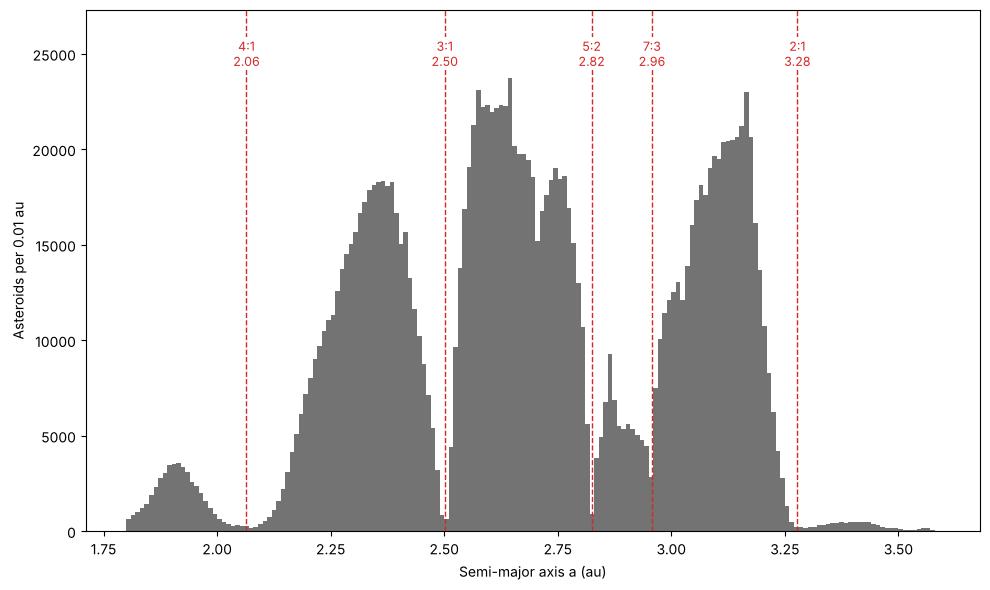

In [3]:
A_JUP = 5.2026
res = {'4:1': (4, 1), '3:1': (3, 1), '5:2': (5, 2), '7:3': (7, 3), '2:1': (2, 1)}
belt = df.a[(df.a > 1.8) & (df.a < 3.6)]
fig, ax = plt.subplots(figsize=(10, 6))
counts, _, _ = ax.hist(belt, bins=np.arange(1.8, 3.6, 0.01), color='0.45')
for name, (n, m) in res.items():
    x = A_JUP * (m / n) ** (2 / 3)
    ax.axvline(x, color='tab:red', ls='--', lw=1)
    ax.text(x, counts.max() * 1.02, f'{name}\n{x:.2f}', color='tab:red', ha='center', va='bottom', fontsize=9,
            bbox=dict(fc='white', ec='none', pad=1))
ax.set_ylim(0, counts.max() * 1.15)
ax.set(xlabel='Semi-major axis a (au)', ylabel='Asteroids per 0.01 au'); plt.tight_layout(); plt.show()

Counts drop sharply at the 4:1, 3:1, 5:2 and 2:1 resonances. The 7:3 line sits on a smaller dip, so I would not call it a clean gap. The small bump inside 1.8-2.0 au is a separate population I have not identified. This uses each asteroid's *current* orbit, which blurs the gaps; averaged ("proper") orbits would likely look sharper.

## 3. New designations per half-month, 2024-2026
A designation such as `2025 AQ10` encodes the date of the first reported observation: year, then a half-month letter (A = Jan 1-15, B = Jan 16-31, ... Y = Dec 16-31, no letter I).

2024    26246
2025    73305
2026    21108
Name: count, dtype: int64


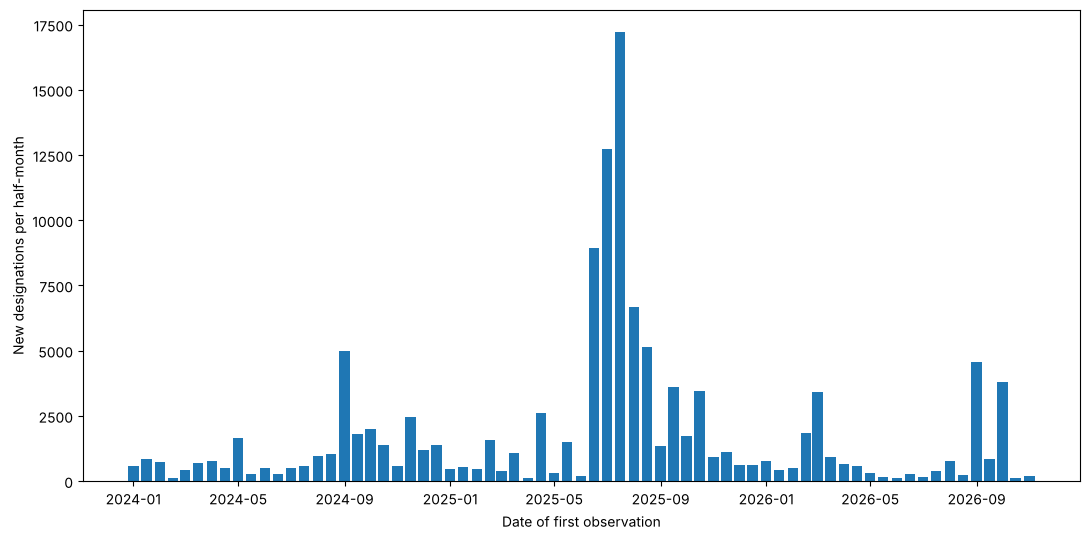

In [4]:
HALF = 'ABCDEFGHJKLMNOPQRSTUVWXY'
pat = re.compile(r'(\d{4}) ([A-HJ-Y])[A-HJ-Z]\d*$')       # skips survey codes like "2025 T-3"
rows = []
for s in df.name.dropna():
    m = pat.search(s)
    if m and 2024 <= int(m.group(1)) <= 2026:
        i = HALF.index(m.group(2))
        rows.append(pd.Timestamp(int(m.group(1)), i // 2 + 1, 1 if i % 2 == 0 else 16))
c = pd.Series(rows).value_counts().sort_index()
print(c.groupby(c.index.year).sum())
plt.figure(figsize=(11, 5.5)); plt.bar(c.index, c.values, width=12, color='tab:blue')
plt.ylabel('New designations per half-month'); plt.xlabel('Date of first observation'); plt.tight_layout(); plt.show()

There is a large spike in mid-2025 (over 17,000 in one half-month), but counts in 2026 are much lower. **Open questions:** the cause of the spike and of the 2026 drop. A designation shows when an object was first observed, not who found it, so this chart does not by itself show that Rubin is responsible. Next step: fetch observations for a sample of 2026 objects and check how many carry Rubin's observatory code (X05). The November 2026 bars are incomplete.

*Data: Minor Planet Center, MPCORB.*